Decision tree dibagi 2 : 

- Decision Tree Regressor : 
    1. Digunakan untuk regresi, menghasilkan prediksi nilai kontinu (float atau int)
    2. Contoh : memprediksi harga rumah, suhu atau penjualan. 

- Decision Tree Classifier 
    1. Digunakan untuk klasifikasi, menghasilkan kelas atau kategori.
    2. Contoh : mengklasifikasikan seseorang akan membeli produk(Ya/Tidak)

In [180]:
# Decision Tree Regressor 

import pandas as pd 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import MinMaxScaler 
from sklearn.tree import DecisionTreeRegressor 

df = pd.read_csv("death_clean.csv")
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [181]:
x = df[["Cause", "Type"]] # fitur
y = df[["Total Deaths"]] # target

x_encoded = pd.get_dummies(x, columns=["Cause", "Type"])

scaler = MinMaxScaler()
y_norm = scaler.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_norm, test_size=0.3, random_state=42)

In [182]:
model = DecisionTreeRegressor()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([0.12955149, 0.07946554, 0.04360056, 0.06153305, 0.10873093,
       0.10873093, 0.07946554, 0.        , 0.00803697, 0.0323488 ,
       0.        , 0.60970464, 0.07946554, 0.17862166, 0.41772152,
       0.07946554, 0.        , 0.60970464, 0.01054852, 0.0323488 ,
       0.03164557, 0.27707454, 0.30098453, 0.0121894 , 0.07946554,
       0.        , 0.        , 0.02756681, 0.10423504, 0.10423504,
       0.01172058, 0.        , 0.        , 0.07946554, 0.03248945,
       0.07946554, 0.60970464, 0.27707454, 0.08415377, 0.08415377,
       0.12955149, 0.        , 0.0140647 , 0.07946554, 0.03248945,
       0.35864979, 0.10873093, 0.10423504, 0.02390999, 0.10423504,
       0.03164557, 0.02208158, 0.        , 0.        , 0.01312705,
       0.00225035, 0.10873093, 0.10873093, 0.1203171 , 0.69057665,
       0.        , 0.        , 0.01898734, 0.28691983, 0.06153305,
       0.60970464, 0.19878106, 0.35864979, 0.10873093, 0.1203171 ,
       0.07946554, 0.        , 0.01312705, 0.00843882, 0.07946

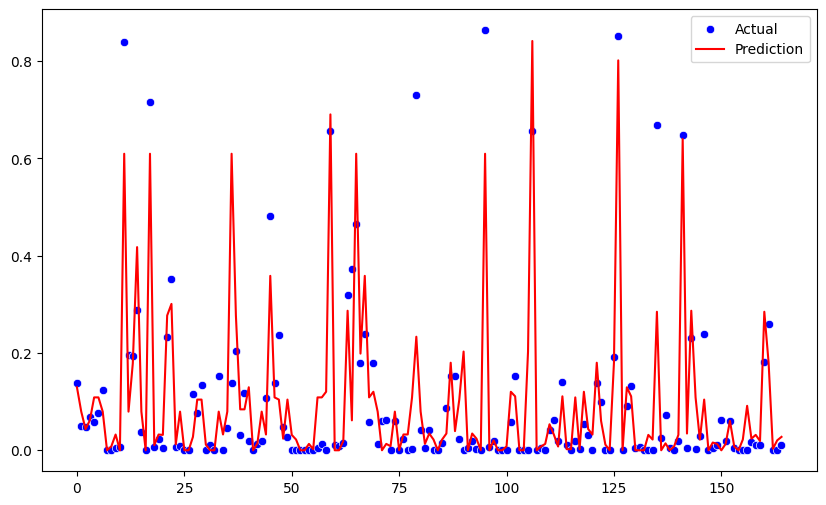

In [183]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.scatterplot(x=range(len(y_test)), y = y_test, color = "blue", label="Actual")
sns.lineplot(x=range(len(y_test)), y = y_pred, color = "red", label="Prediction")
plt.show()

In [184]:
model.score(x_test, y_test)

0.7503779883924386

In [185]:
x_encoded.columns

Index(['Cause_AIDS', 'Cause_Abrasi Air Laut', 'Cause_Aksi Teror dan Sabotase',
       'Cause_Angin Puting Beliung', 'Cause_Angin Siklon Tropis',
       'Cause_Angin Topan',
       'Cause_Angin Topan / Angin Puting Beliung / Angin Puyuh',
       'Cause_Angin kencang',
       'Cause_Angin siklon tropis (angin kencang dan angin puting beliung)',
       'Cause_Antraks',
       ...
       'Cause_Rubella', 'Cause_Tanah Longsor', 'Cause_Tersambar Petir',
       'Cause_Tetanus', 'Cause_Tetanus Neonatorium', 'Cause_Tsunami',
       'Cause_Wabah Penyakit (Epidemi)', 'Type_Bencana Alam',
       'Type_Bencana Non Alam dan Penyakit', 'Type_Bencana Sosial'],
      dtype='object', length=148)

In [186]:
import graphviz 
from io import StringIO 
from sklearn.tree import export_graphviz 

x_encoded.columns = x_encoded.columns.str.replace('[^a-zA-Z0-9]', "_", regex=True)

dot_data = StringIO()
export_graphviz(model, out_file=dot_data, feature_names=x_encoded.columns, filled=True, rounded=True, special_characters=False)

graph = graphviz.Source(dot_data.getvalue())
graph.render("Decision_tree", format="pdf")

'Decision_tree.pdf'

In [187]:
# Decision Tree Classifier

import numpy as np 

np.random.seed(42)
data_size = 200 
age = np.random.randint(18, 60, size = data_size)
income = np.random.randint(20000, 120000, size = data_size)
education = np.random.randint(1, 5, size = data_size)
purchase = np.random.randint(0, 2, size=data_size)

df = pd.DataFrame({
    "Age" : age, 
    "Income" : income, 
    "Education" : education,
    "Purchase" : purchase
})

df

,Age,Income,Education,Purchase
0,56,45342,2,1
1,46,57157,3,0
2,32,87863,2,0
3,25,72083,3,1
4,38,85733,4,1
...,...,...,...,...
195,23,75609,3,1
196,49,116825,1,1
197,21,76661,3,1
198,28,51024,4,1


In [188]:
x = df[["Age", "Income", "Education"]]
y = df[["Purchase"]]

scaler_prenjualan = MinMaxScaler()
x_scaled = scaler_prenjualan.fit_transform(x)

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.3, random_state=42)

In [189]:
from sklearn.tree import DecisionTreeClassifier

model_kalsifikasi = DecisionTreeClassifier(random_state=42, ccp_alpha=0.01) 
model_kalsifikasi.fit(x_train, y_train)
y_pred = model_kalsifikasi.predict(x_test)

In [190]:
score = model_kalsifikasi.score(x_test, y_test)
score

0.5833333333333334

In [201]:
df_baru = pd.DataFrame({
    "Actual" : y_test["Purchase"].values, 
    "Prediction" : y_pred
})
df_baru

,Actual,Prediction
0,0,0
1,0,1
2,1,0
3,1,1
4,0,0
5,0,0
6,0,0
7,0,1
8,1,1
9,1,0
